# Final Project: การวิเคราะห์ปัจจัยที่สัมพันธ์กับผลลัพธ์ของการสั่งอาหารออนไลน์
> 1145 201 คณิตศาสตร์สำหรับวิทยาการข้อมูล | Semester 1/2568

**กลุ่ม:**
- สมาชิกที่ 1: นายศิขรินทร์ ภูติโส (68114540616)

**Dataset:** Online Food Ordering Dataset, Kaggle  
แหล่งข้อมูลตาม Template: https://www.kaggle.com/datasets/srisyra02/online-food-ordering-dataset

**Problem Statement:**  
Dataset นี้มีข้อมูลลักษณะและพฤติกรรมของลูกค้า เช่น อายุ อาชีพ รายได้ ขนาดครอบครัว ประเภทลูกค้า ตำแหน่งที่อยู่ และ Feedback พร้อมตัวแปร `Output` ที่มีค่า `Yes/No` จึงต้องการวิเคราะห์ว่าปัจจัยเหล่านี้มีความสัมพันธ์กับค่า `Output` อย่างไร และสร้างแบบจำลอง Classification เพื่อจำแนก `Output` เป็น 2 กลุ่ม

> หมายเหตุ: ในโครงงานนี้จะใช้ความหมายของ `Output` ตามค่าที่ปรากฏใน Dataset โดยไม่ตีความเกินกว่าข้อมูลที่มี และจะพิจารณาความเสี่ยงของ `Feedback` แยกต่างหาก เนื่องจากอาจเป็นข้อมูลที่เกิดหลังการใช้บริการ

---

| CLO | ส่วนที่ครอบคลุม | Status |
|-----|----------------|--------|
| CLO1 (Linear Algebra) | Part 2 — PCA | ✅ |
| CLO2 (Statistical Learning) | Part 3 — Distribution, Correlation, Bias-Variance | ✅ |
| CLO3 (Regression/Classification) | Part 4 — Logistic Regression + KNN + Sensitivity Check | ✅ |
| CLO4 (Model Selection) | Part 5 — 5-Fold Cross-Validation + 1-SE Rule + Final Test | ✅ |


In [12]:
# ─── Import libraries ──────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
    classification_report
)

np.random.seed(42)
def make_preprocessor(numeric_cols, categorical_cols):
    return ColumnTransformer([
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), numeric_cols),
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
        ]), categorical_cols)
    ])

print('Ready.')


Ready.


In [13]:
# ─── ตั้งค่าฟอนต์ภาษาไทยมาตรฐาน Sarabun สำหรับ Matplotlib ──────────────────
import os
import shutil
import matplotlib as mpl
import matplotlib.font_manager as fm
import urllib.request

font_url = "https://github.com/google/fonts/raw/main/ofl/sarabun/Sarabun-Regular.ttf"
font_path = "Sarabun-Regular.ttf"

try:
    urllib.request.urlretrieve(font_url, font_path)
    print("ดาวน์โหลดฟอนต์สำเร็จ!")
    matplotlib_font_dir = os.path.join(mpl.__path__[0], 'mpl-data', 'fonts', 'ttf')
    shutil.copy(font_path, matplotlib_font_dir)


    fm.fontManager.addfont(font_path)
    shutil.rmtree(mpl.get_cachedir(), ignore_errors=True)


    mpl.rc('font', family='Sarabun', size=13)
    mpl.rcParams['axes.unicode_minus'] = False
    print("ตั้งค่าระบบดึงฟอนต์ Sarabun สำเร็จ!")
except Exception as e:
    print(f"เกิดข้อผิดพลาดในการตั้งค่าฟอนต์: {e}")
    print("กำลังสลับไปใช้ฟอนต์ Tahoma ซึ่งมีมาให้ในระบบอยู่แล้วเพื่อป้องกันการแครช...")
    mpl.rc('font', family='Tahoma', size=13)

ดาวน์โหลดฟอนต์สำเร็จ!
ตั้งค่าระบบดึงฟอนต์ Sarabun สำเร็จ!


---
## Part 1: Dataset Overview และ EDA เบื้องต้น

ในส่วนนี้ให้โหลด dataset, แสดง basic statistics, และทำ EDA เบื้องต้นเพื่อเข้าใจข้อมูลก่อนวิเคราะห์

**สิ่งที่ต้องทำ:**
- โหลด dataset และแสดง shape, dtypes, missing values
- แสดง descriptive statistics ด้วย `.describe()`
- Plot distribution ของ target variable
- Plot correlation heatmap หรือ scatter matrix

**การเตรียมข้อมูล :**
1. ตรวจสอบ duplicate rows และลบออก — **ข้อสมมติที่ต้องระบุชัด:** dataset นี้เป็นแบบสำรวจและไม่มี customer ID เฉพาะตัว การนับว่าแถวหนึ่ง "ซ้ำ" ต้องมีค่าตรงกันครบทั้ง 14 คอลัมน์ ซึ่งรวม `latitude`/`longitude`/`Pin code` ที่มีความจำเพาะสูง (77 ค่าไม่ซ้ำจาก 388 แถว) การจับคู่ที่ตรงกันทั้งหมดพร้อมกันจึงมีโอกาสเกิดโดยบังเอิญต่ำ เราจึงเลือก**สมมติว่าเป็น record ซ้ำจริง**และลบออก แต่ขอบันทึกไว้ตรงนี้ว่าเป็นข้อสมมติ ไม่ใช่ข้อเท็จจริงที่ยืนยันได้ 100% เพราะไม่มี ID ยืนยัน
2. ทำความสะอาดข้อความ (`Feedback` มีช่องว่างเกิน เช่น `'Negative '`)
3. ตัด `Unnamed: 13` ออก เพราะซ้ำกับ `Output` (Target) ทุกแถว
4. **ตัด `Pin code` ออกจากการสร้างโมเดล** — เดิมมีการ one-hot encode Pin code (77 หมวด) ซึ่งซ้ำซ้อนกับ `latitude`/`longitude` ที่บอกตำแหน่งอยู่แล้ว และทำให้มิติข้อมูลบวมจาก 12 เป็น 105 มิติ (73% มาจาก Pin code อย่างเดียว) บนข้อมูลแค่ 285 แถว เสี่ยง overfit สูงมาก (เห็นได้จาก coefficient ของ Logistic Regression รอบก่อนที่ค่าที่ใหญ่ที่สุดกลับเป็น Pin code เฉพาะจุด ไม่ใช่ตัวแปร demographic ที่มีความหมาย) จึงเก็บ Pin code ไว้ดูอ้างอิงเฉยๆ แต่ไม่ใช้เป็น feature ในการสร้างโมเดล
5. คำนวณ **Overall Majority Proportion** ไว้สำหรับอธิบาย class imbalance และใช้เป็นข้อมูลประกอบในการวิเคราะห์ โดย **Final Test Baseline จะคำนวณจาก Training Set เท่านั้น** แล้วนำไปประเมินบน Test Set

In [14]:
# ─── โหลด Dataset จาก Kaggle + ตรวจสอบและทำความสะอาดข้อมูล ─────────────────
# แหล่งข้อมูล: https://www.kaggle.com/datasets/srisyra02/online-food-ordering-dataset

import os
import glob
import zipfile
import urllib.request

KAGGLE_DATASET = 'srisyra02/online-food-ordering-dataset'
KAGGLE_SOURCE_URL = 'https://www.kaggle.com/datasets/srisyra02/online-food-ordering-dataset'
ZIP_PATH = '/content/online-food-ordering-dataset.zip'
DATA_DIR = '/content/online_food_ordering_dataset'

if not os.path.exists(ZIP_PATH):
    print('กำลังดาวน์โหลด Dataset จาก Kaggle...')
    download_url = f'https://www.kaggle.com/api/v1/datasets/download/{KAGGLE_DATASET}'
    urllib.request.urlretrieve(download_url, ZIP_PATH)
    print('ดาวน์โหลด Dataset สำเร็จ')



os.makedirs(DATA_DIR, exist_ok=True)
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    z.extractall(DATA_DIR)

csv_candidates = sorted(glob.glob(os.path.join(DATA_DIR, '**', '*.csv'), recursive=True))
if not csv_candidates:
    raise FileNotFoundError('ไม่พบไฟล์ CSV ภายใน Kaggle Dataset')

required_columns = {'Output', 'Feedback'}
csv_path = None
for path in csv_candidates:
    try:
        cols = set(pd.read_csv(path, nrows=0).columns)
        if required_columns.issubset(cols):
            csv_path = path
            break
    except Exception:
        continue

if csv_path is None:
    raise FileNotFoundError(
        'พบ CSV แต่ไม่พบไฟล์ที่มีคอลัมน์ Output และ Feedback ตาม Dataset ที่คาดไว้\n'
        f'CSV ที่พบ: {csv_candidates}'
    )

df_raw = pd.read_csv(csv_path)

print(f'Kaggle Dataset: {KAGGLE_SOURCE_URL}')
print(f'CSV ที่ใช้: {csv_path}')
print(f'Original Shape: {df_raw.shape}')
print(f'Original Duplicate Rows: {df_raw.duplicated().sum()}')
print('\nOriginal Missing Values:')
display(df_raw.isnull().sum().to_frame('จำนวน Missing'))


df = df_raw.copy()

n_dup = df.duplicated().sum()
df = df.drop_duplicates().copy()

df['Feedback'] = df['Feedback'].astype(str).str.strip()
df['Output'] = df['Output'].astype(str).str.strip()


if 'Unnamed: 13' in df.columns:
    same_as_output = (
        df['Unnamed: 13'].astype(str).str.strip().values
        == df['Output'].astype(str).str.strip().values
    ).all()
    print(f'Unnamed: 13 เป็นข้อมูลซ้ำกับ Output ทุกแถวหรือไม่: {same_as_output}')
    if same_as_output:
        df = df.drop(columns=['Unnamed: 13'])


if 'Pin code' in df.columns:
    df['Pin code'] = df['Pin code'].astype(str)

print(f'Cleaned Shape: {df.shape}')
print(f'Removed Duplicate Rows: {n_dup}')
print('\nColumns:')
print(df.columns.tolist())

print('\nData Types:')
display(df.dtypes.to_frame('dtype'))

print('\nMissing Values After Cleaning:')
display(df.isnull().sum().to_frame('จำนวน Missing'))

display(df.head())


numeric_cols = ['Age', 'Family size', 'latitude', 'longitude']
categorical_cols = ['Gender', 'Marital Status', 'Occupation', 'Monthly Income',
                     'Educational Qualifications', 'Customer Type', 'Feedback']

X = df[numeric_cols + categorical_cols]
y = (df['Output'] == 'Yes').astype(int)

print(f'\nจำนวน feature columns ที่ใช้สร้างโมเดล: {X.shape[1]} '
      f'(numeric {len(numeric_cols)} + categorical {len(categorical_cols)}, ไม่รวม Pin code)')


baseline_acc = y.value_counts(normalize=True).max()
print(f'\nสัดส่วน Output:')
print(df['Output'].value_counts(normalize=True))
print(f'Overall Majority Proportion = {baseline_acc:.4f} '
      f'({baseline_acc*100:.2f}%)')
print('หมายเหตุ: ค่านี้ใช้เพื่ออธิบาย class imbalance; Final Test Baseline จะคำนวณจาก Training Set')


Kaggle Dataset: https://www.kaggle.com/datasets/srisyra02/online-food-ordering-dataset
CSV ที่ใช้: /content/online_food_ordering_dataset/online food delivery dataset.csv
Original Shape: (388, 14)
Original Duplicate Rows: 103

Original Missing Values:


,จำนวน Missing
Age,0
Gender,0
Marital Status,0
Occupation,0
Monthly Income,0
Educational Qualifications,0
Family size,0
Customer Type,0
latitude,0
longitude,0


Unnamed: 13 เป็นข้อมูลซ้ำกับ Output ทุกแถวหรือไม่: True
Cleaned Shape: (285, 13)
Removed Duplicate Rows: 103

Columns:
['Age', 'Gender', 'Marital Status', 'Occupation', 'Monthly Income', 'Educational Qualifications', 'Family size', 'Customer Type', 'latitude', 'longitude', 'Pin code', 'Output', 'Feedback']

Data Types:


,dtype
Age,int64
Gender,object
Marital Status,object
Occupation,object
Monthly Income,object
Educational Qualifications,object
Family size,int64
Customer Type,object
latitude,float64
longitude,float64



Missing Values After Cleaning:


,จำนวน Missing
Age,0
Gender,0
Marital Status,0
Occupation,0
Monthly Income,0
Educational Qualifications,0
Family size,0
Customer Type,0
latitude,0
longitude,0


,Age,Gender,Marital Status,Occupation,Monthly Income,Educational Qualifications,Family size,Customer Type,latitude,longitude,Pin code,Output,Feedback
0,20,Female,Single,Student,No Income,Post Graduate,4,Frequent,12.9766,77.5993,560001,Yes,Positive
1,24,Female,Single,Student,Below Rs.10000,Graduate,3,Regular,12.9770,77.5773,560009,Yes,Positive
2,22,Male,Single,Student,Below Rs.10000,Post Graduate,3,Regular,12.9551,77.6593,560017,Yes,Negative
3,22,Female,Single,Student,No Income,Graduate,6,Frequent,12.9473,77.5616,560019,Yes,Positive
4,22,Male,Single,Student,Below Rs.10000,Post Graduate,4,Frequent,12.9850,77.5533,560010,Yes,Positive



จำนวน feature columns ที่ใช้สร้างโมเดล: 11 (numeric 4 + categorical 7, ไม่รวม Pin code)

สัดส่วน Output:
Output
Yes    0.761404
No     0.238596
Name: proportion, dtype: float64
Overall Majority Proportion = 0.7614 (76.14%)
หมายเหตุ: ค่านี้ใช้เพื่ออธิบาย class imbalance; Final Test Baseline จะคำนวณจาก Training Set


Descriptive Statistics (all variables):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,285.0,NaN,NaN,NaN,24.677193,3.040977,18.0,23.0,24.0,26.0,33.0
Gender,285,2,Male,164,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Marital Status,285,3,Single,189,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Occupation,285,4,Student,144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Monthly Income,285,5,No Income,131,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Educational Qualifications,285,5,Graduate,126,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Family size,285.0,NaN,NaN,NaN,3.270175,1.361178,1.0,2.0,3.0,4.0,6.0
Customer Type,285,3,Regular,162,NaN,NaN,NaN,NaN,NaN,NaN,NaN
latitude,285.0,NaN,NaN,NaN,12.973429,0.043964,12.8652,12.9438,12.977,12.998,13.102
longitude,285.0,NaN,NaN,NaN,77.597593,0.053557,77.4842,77.5635,77.5877,77.6227,77.7582



Target Distribution:


,จำนวน
Output,
Yes,217
No,68


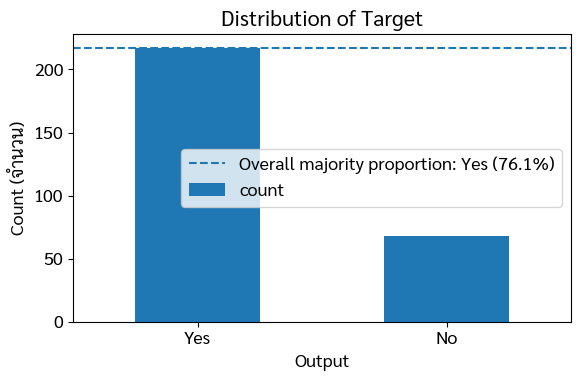

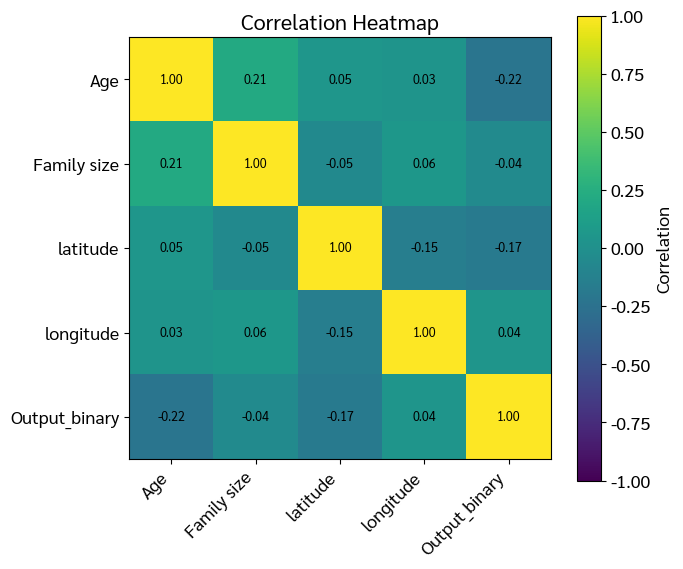

EDA Summary:
- Dataset หลังลบ duplicate เหลือ 285 แถว และ 13 คอลัมน์
- Missing values เป็น 0 ในทุกคอลัมน์หลังการตรวจสอบ
- Output มี 2 classes (Yes/No) และไม่สมดุลกัน (Baseline Accuracy = 76.14%)


In [15]:
# ─── Descriptive Statistics + Visualization ───────────────────────
print('Descriptive Statistics (all variables):')
display(df.describe(include='all').T)

print('\nTarget Distribution:')
target_counts = df['Output'].value_counts()
display(target_counts.to_frame('จำนวน'))

fig, ax = plt.subplots(figsize=(6, 4))
target_counts.reindex(['Yes', 'No']).plot(kind='bar', ax=ax)
ax.axhline(len(df) * baseline_acc, linestyle='--',
           label=f'Overall majority proportion: Yes ({baseline_acc*100:.1f}%)')
ax.set_title('Distribution of Target')
ax.set_xlabel('Output')
ax.set_ylabel('Count (จำนวน)')
ax.tick_params(axis='x', rotation=0)
ax.legend()
plt.tight_layout()
plt.show()


eda_df = df.copy()
eda_df['Output_binary'] = eda_df['Output'].map({'No': 0, 'Yes': 1})

numeric_eda = ['Age', 'Family size', 'latitude', 'longitude', 'Output_binary']
corr_matrix = eda_df[numeric_eda].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr_matrix, vmin=-1, vmax=1)
ax.set_xticks(range(len(numeric_eda)))
ax.set_yticks(range(len(numeric_eda)))
ax.set_xticklabels(numeric_eda, rotation=45, ha='right')
ax.set_yticklabels(numeric_eda)
for i in range(len(numeric_eda)):
    for j in range(len(numeric_eda)):
        ax.text(j, i, f'{corr_matrix.iloc[i, j]:.2f}', ha='center', va='center', fontsize=9)
ax.set_title('Correlation Heatmap')
fig.colorbar(im, ax=ax, label='Correlation')
plt.tight_layout()
plt.show()

print('EDA Summary:')
print(f'- Dataset หลังลบ duplicate เหลือ {df.shape[0]} แถว และ {df.shape[1]} คอลัมน์')
print('- Missing values เป็น 0 ในทุกคอลัมน์หลังการตรวจสอบ')
print(f'- Output มี 2 classes (Yes/No) และไม่สมดุลกัน (Baseline Accuracy = {baseline_acc*100:.2f}%)')


---
## Part 2: CLO1 — Linear Algebra Analysis

### Task A: PCA (Principal Component Analysis)

เลือก **PCA** เพื่อศึกษาว่า feature matrix ที่มีทั้งตัวแปรตัวเลขและตัวแปรหมวดหมู่สามารถสรุปให้อยู่ในมิติที่น้อยลงได้มากเพียงใด โดยตัวแปรเชิงตัวเลขถูก Standardize และตัวแปรเชิงหมวดหมู่ถูกแปลงด้วย One-Hot Encoding ก่อนทำ PCA จากนั้นใช้ Scree Plot และ 2D visualization เพื่อดูโครงสร้างความแปรปรวนและการแยกกลุ่มของ Target


Original feature columns: 11
Encoded feature dimensions: 28  (ไม่รวม Pin code)
PC1 explained variance: 23.38%
PC1-PC2 cumulative variance: 38.81%
First 5 PCs cumulative variance: 71.08%


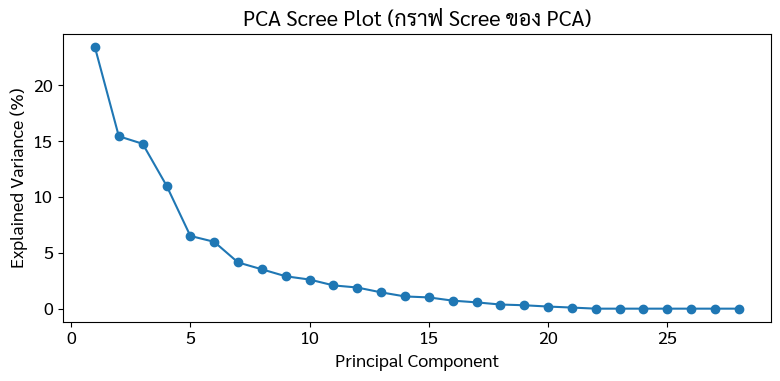

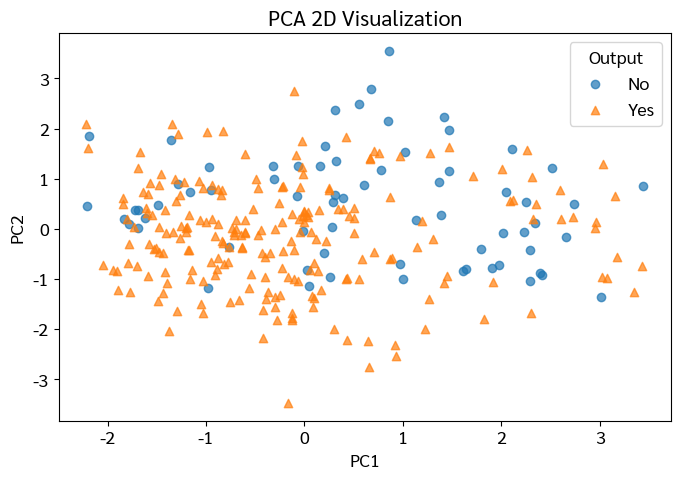

Top 8 features บน PC1:


,|Loading| PC1
num__Age,0.610978
num__Family size,0.462738
cat__Occupation_Student,0.268173
cat__Marital Status_Single,0.259209
cat__Marital Status_Married,0.247888
cat__Customer Type_Frequent,0.199426
cat__Monthly Income_No Income,0.198220
cat__Customer Type_Regular,0.173715


Top 8 features บน PC2:


,|Loading| PC2
num__latitude,0.632367
num__longitude,0.532124
num__Family size,0.331956
num__Age,0.321782
cat__Customer Type_Frequent,0.160543
cat__Marital Status_Single,0.120094
cat__Customer Type_Regular,0.113920
cat__Marital Status_Married,0.100572


In [16]:
# ─── CLO1: PCA ────────────────────────────────────────────────────
preprocessor_pca = make_preprocessor(numeric_cols, categorical_cols)
X_encoded = preprocessor_pca.fit_transform(X)
feature_names = preprocessor_pca.get_feature_names_out()

print(f'Original feature columns: {X.shape[1]}')
print(f'Encoded feature dimensions: {X_encoded.shape[1]}  (ไม่รวม Pin code)')

pca = PCA()
X_pca = pca.fit_transform(X_encoded)

explained = pca.explained_variance_ratio_
cumulative = np.cumsum(explained)

print(f'PC1 explained variance: {explained[0]*100:.2f}%')
print(f'PC1-PC2 cumulative variance: {cumulative[1]*100:.2f}%')
print(f'First 5 PCs cumulative variance: {cumulative[4]*100:.2f}%')

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, len(explained) + 1), explained * 100, marker='o')
ax.set_title('PCA Scree Plot (กราฟ Scree ของ PCA)')
ax.set_xlabel('Principal Component')
ax.set_ylabel('Explained Variance (%)')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 5))
for label, marker in [(0, 'o'), (1, '^')]:
    mask = y.values == label
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1],
               label='No' if label == 0 else 'Yes', alpha=0.7, marker=marker)
ax.set_title('PCA 2D Visualization')
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.legend(title='Output')
plt.tight_layout()
plt.show()

pc1_loading = pd.Series(pca.components_[0], index=feature_names)
pc2_loading = pd.Series(pca.components_[1], index=feature_names)
print('Top 8 features บน PC1:')
display(pc1_loading.abs().sort_values(ascending=False).head(8).to_frame('|Loading| PC1'))
print('Top 8 features บน PC2:')
display(pc2_loading.abs().sort_values(ascending=False).head(8).to_frame('|Loading| PC2'))

**Insight จาก CLO1 Analysis:**

หลังตัด `Pin code` ออกจากชุด feature สำหรับโมเดลและ PCA ตัวแปรที่เหลือถูกเข้ารหัสเป็น **28 dimensions** โดย PC1 อธิบายความแปรปรวนได้ **23.38%** และ 5 PC แรกอธิบายได้ **71.08%** ของความแปรปรวนทั้งหมด

- **PC1** มี loading สูงใน `Age`, `Family size` และบางระดับของ `Occupation`/`Marital Status` จึงอาจตีความได้ว่าเป็นแกนที่เกี่ยวข้องกับลักษณะทางประชากรและครอบครัว
- **PC2** มี loading สูงใน `latitude` และ `longitude` จึงสะท้อนองค์ประกอบด้านตำแหน่งทางภูมิศาสตร์
- Scatter plot ของ PC1–PC2 ยังมีการทับซ้อนระหว่างกลุ่ม Yes/No ค่อนข้างมาก จึงยังไม่เห็นการแยกกลุ่มอย่างชัดเจนในสององค์ประกอบแรก

**หมายเหตุ:** การตีความ loading เป็นการอธิบายเชิงโครงสร้างของข้อมูล ไม่ได้หมายความว่า PC นั้นเป็น “สาเหตุ” ของ Output


---
## Part 3: CLO2 — Statistical Learning

**สิ่งที่ต้องทำ:**
- แสดง distribution ของ features สำคัญ
- Identify features ที่ correlate กับ target มากที่สุด
- แสดง error สำหรับ model complexity ต่างๆ (Bias-Variance)
- เลือก hyperparameter `k` ด้วย 5-Fold Cross-Validation โดยใช้ **Training Set เท่านั้น**

### Dataset เหมาะกับ Regression หรือ Classification?

Dataset นี้เหมาะกับ **Classification** เพราะตัวแปรเป้าหมาย `Output` เป็นข้อมูลเชิงหมวดหมู่ที่มี 2 ค่า คือ `Yes` และ `No` ดังนั้นโจทย์คือการจำแนกข้อมูลออกเป็น 2 กลุ่ม

> สำหรับ Classification ส่วน Bias-Variance จะใช้ **Classification Error Rate** แทน MSE เพื่อให้ metric สอดคล้องกับชนิดของปัญหา


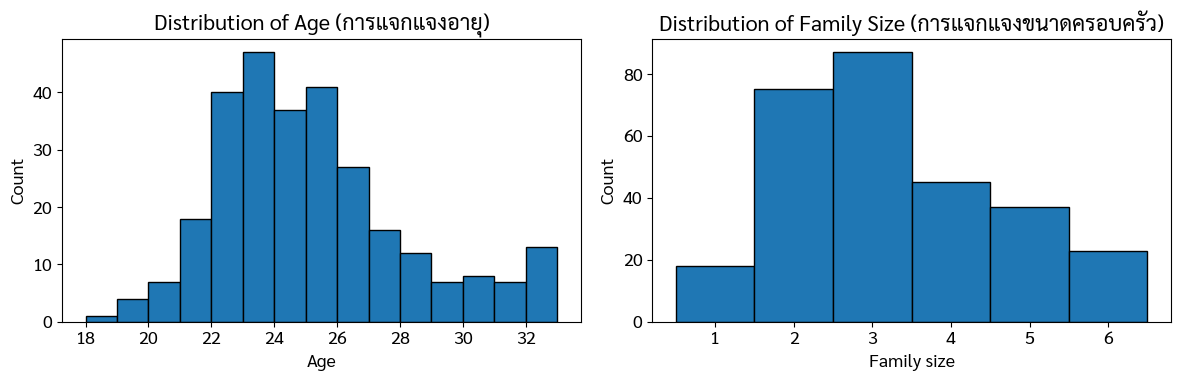

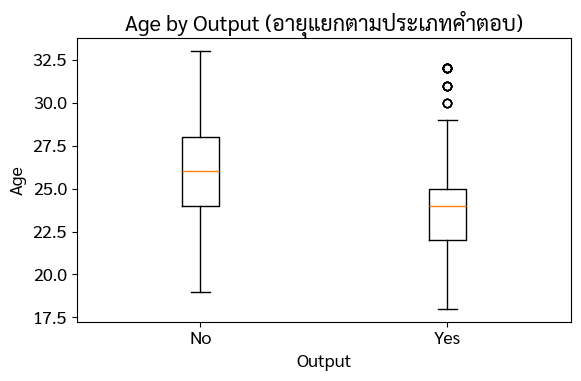

Top 10 encoded features by absolute correlation with Output:


,Feature,Correlation,Abs_Correlation
0,cat__Feedback_Negative,-0.548606,0.548606
1,cat__Feedback_Positive,0.548606,0.548606
2,cat__Marital Status_Single,0.280335,0.280335
3,cat__Occupation_Student,0.269338,0.269338
4,cat__Marital Status_Married,-0.236715,0.236715
5,num__Age,-0.224950,0.224950
6,cat__Occupation_Employee,-0.202622,0.202622
7,cat__Monthly Income_No Income,0.202450,0.202450
8,num__latitude,-0.173175,0.173175
9,cat__Educational Qualifications_Post Graduate,0.146399,0.146399


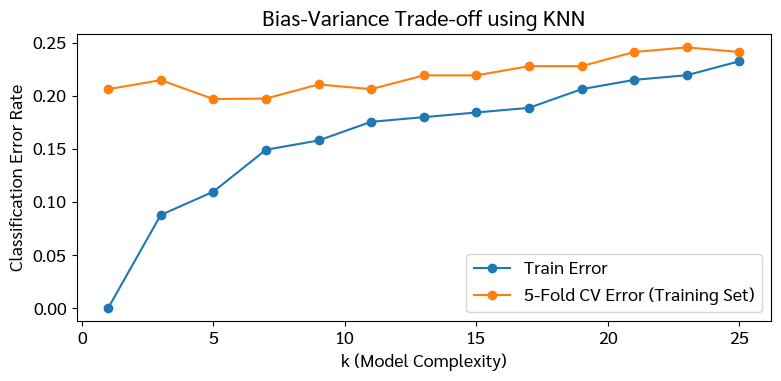

,k,CV Accuracy
0,1,0.793913
1,3,0.785314
2,5,0.803092
3,7,0.802705
4,9,0.789372
5,11,0.793816
6,13,0.780870
7,15,0.780870
8,17,0.772174
9,19,0.772174


k ที่ได้ CV Accuracy สูงสุดจาก Training Set: k = 5 (CV Accuracy = 0.8031)
หมายเหตุ: Test Set ยังไม่ได้ถูกใช้เพื่อเลือก k


In [17]:
# ─── CLO2: Statistical Analysis ───────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(df['Age'], bins=15, edgecolor='black')
axes[0].set_title('Distribution of Age (การแจกแจงอายุ)')
axes[0].set_xlabel('Age')
axes[0].set_ylabel('Count')

axes[1].hist(df['Family size'], bins=range(
    int(df['Family size'].min()), int(df['Family size'].max()) + 2
), edgecolor='black', align='left')
axes[1].set_title('Distribution of Family Size (การแจกแจงขนาดครอบครัว)')
axes[1].set_xlabel('Family size')
axes[1].set_ylabel('Count')
plt.tight_layout()
plt.show()


groups = [df.loc[df['Output'] == 'No', 'Age'], df.loc[df['Output'] == 'Yes', 'Age']]
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot(groups, tick_labels=['No', 'Yes'])
ax.set_title('Age by Output (อายุแยกตามประเภทคำตอบ)')
ax.set_xlabel('Output')
ax.set_ylabel('Age')
plt.tight_layout()
plt.show()


ohe_preprocessor = ColumnTransformer([
    ('num', 'passthrough', numeric_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
])
X_onehot = ohe_preprocessor.fit_transform(X)
encoded_names = ohe_preprocessor.get_feature_names_out()

corr_values = []
for i in range(X_onehot.shape[1]):
    col = X_onehot[:, i]
    corr = np.corrcoef(col, y.values)[0, 1] if np.std(col) > 0 else np.nan
    corr_values.append(corr)

corr_target = pd.Series(corr_values, index=encoded_names).dropna()
top_corr = corr_target.loc[corr_target.abs().sort_values(ascending=False).head(10).index]

print('Top 10 encoded features by absolute correlation with Output:')
display(pd.DataFrame({
    'Feature': top_corr.index,
    'Correlation': top_corr.values,
    'Abs_Correlation': top_corr.abs().values
}).sort_values('Abs_Correlation', ascending=False))


X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)


k_values = list(range(1, 26, 2))
train_err, cv_err = [], []
cv_select = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for k in k_values:
    knn_model = Pipeline([
        ('preprocess', make_preprocessor(numeric_cols, categorical_cols)),
        ('model', KNeighborsClassifier(n_neighbors=k))
    ])
    knn_model.fit(X_train, y_train)
    train_err.append(1 - accuracy_score(y_train, knn_model.predict(X_train)))

    scores = cross_val_score(
        knn_model, X_train, y_train,
        cv=cv_select, scoring='accuracy'
    )
    cv_err.append(1 - scores.mean())

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(k_values, train_err, marker='o', label='Train Error')
ax.plot(k_values, cv_err, marker='o', label='5-Fold CV Error (Training Set)')
ax.set_title('Bias-Variance Trade-off using KNN')
ax.set_xlabel('k (Model Complexity)')
ax.set_ylabel('Classification Error Rate')
ax.legend()
plt.tight_layout()
plt.show()


cv_k_df = pd.DataFrame({
    'k': k_values,
    'CV Accuracy': [1 - e for e in cv_err]
})
display(cv_k_df)

best_k = int(cv_k_df.loc[cv_k_df['CV Accuracy'].idxmax(), 'k'])
best_k_score = float(cv_k_df.loc[cv_k_df['CV Accuracy'].idxmax(), 'CV Accuracy'])

print(
    f'k ที่ได้ CV Accuracy สูงสุดจาก Training Set: k = {best_k} '
    f'(CV Accuracy = {best_k_score:.4f})'
)
print('หมายเหตุ: Test Set ยังไม่ได้ถูกใช้เพื่อเลือก k')


**Insight จาก CLO2 Analysis:**

**Correlation:** `Feedback_Positive`/`Feedback_Negative` เป็นตัวแปรที่มี absolute correlation กับ `Output` สูงที่สุด (ประมาณ **0.55**) ขณะที่ encoded demographic features เช่น `Marital Status_Single` และ `Occupation_Student` มีค่าน้อยกว่ามาก

**Bias-Variance:** เมื่อ `k` เพิ่มขึ้น Train Error โดยทั่วไปจะสูงขึ้น เพราะโมเดลมีความยืดหยุ่นลดลง ส่วน 5-Fold CV Error ช่วยให้ดู trade-off โดยไม่ใช้ Test Set

**การเลือก k:** เมื่อใช้ **5-Fold Cross-Validation เฉพาะ Training Set** จะได้ **k = 5** และ CV Accuracy ประมาณ **80.31%** ดังนั้นค่า `k=5` นี้จะถูกใช้ใน Model 2

**ข้อควรระวัง:** Correlation ไม่ได้บอกเหตุและผล และ `Feedback` อาจเกิดหลังการใช้บริการ หากเป็นเช่นนั้นการนำ Feedback มาใช้ทำนายการตัดสินใจก่อนสั่งอาหารอาจเกิด temporal/target leakage


---
## Part 4: CLO3 — Model Building

**Dataset ของกลุ่มเหมาะกับ:** ☑ Classification

เนื่องจาก Target `Output` เป็น `Yes/No` จึงสร้าง Classification models 2 แบบ:
- **Model 1: Logistic Regression**
- **Model 2: KNN Classifier** โดยใช้ `k = 5` ที่เลือกด้วย 5-Fold Cross-Validation จาก **Training Set เท่านั้น**

ทั้งสองโมเดลใช้ preprocessing เดียวกัน (One-Hot Encoding + Standardization) และไม่ใช้ `Pin code`

เพื่อรักษา Test Set ให้เป็น **ข้อมูลที่ไม่ถูกแตะต้องจนกว่าจะเลือกโมเดลสุดท้าย** ใน Part 4 จะรายงาน Train Accuracy และ **Out-of-Fold (OOF) Accuracy + Confusion Matrix จาก Training Set** แทน Test Accuracy ส่วน **Final Test Accuracy + Confusion Matrix** จะรายงานหลัง Model Selection ใน Part 5


Logistic Regression - Train Accuracy: 0.8640
Logistic Regression - 5-Fold OOF Accuracy: 0.8333

OOF Confusion Matrix (Training Set; แถว=จริง, คอลัมน์=ทำนาย):
[[ 26  28]
 [ 10 164]]


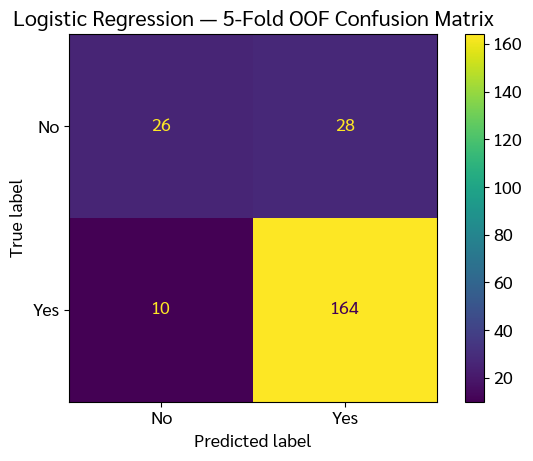

Top 8 coefficients by absolute value:


,|Coefficient|
cat__Feedback_Positive,1.393194
cat__Feedback_Negative,1.384072
cat__Educational Qualifications_School,0.708867
cat__Educational Qualifications_Uneducated,0.613257
cat__Marital Status_Single,0.588447
cat__Occupation_Student,0.584330
cat__Occupation_Self Employeed,0.391161
cat__Occupation_Employee,0.387373


In [18]:
# ─── CLO3: Model 1 — Logistic Regression ─────────────────────────
model1 = Pipeline([
    ('preprocess', make_preprocessor(numeric_cols, categorical_cols)),
    ('model', LogisticRegression(max_iter=2000))
])

model1.fit(X_train, y_train)
train_pred_1 = model1.predict(X_train)
train_acc_1 = accuracy_score(y_train, train_pred_1)

oof_pred_1 = cross_val_predict(
    model1, X_train, y_train, cv=cv_select, method='predict'
)
oof_acc_1 = accuracy_score(y_train, oof_pred_1)
cm1_oof = confusion_matrix(y_train, oof_pred_1)

print(f'Logistic Regression - Train Accuracy: {train_acc_1:.4f}')
print(f'Logistic Regression - 5-Fold OOF Accuracy: {oof_acc_1:.4f}')
print('\nOOF Confusion Matrix (Training Set; แถว=จริง, คอลัมน์=ทำนาย):')
print(cm1_oof)

disp = ConfusionMatrixDisplay(confusion_matrix=cm1_oof, display_labels=['No', 'Yes'])
disp.plot()
plt.title('Logistic Regression — 5-Fold OOF Confusion Matrix')
plt.tight_layout()
plt.show()

feature_names_model1 = model1.fit(X_train, y_train).named_steps['preprocess'].get_feature_names_out()
coef = pd.Series(model1.named_steps['model'].coef_[0], index=feature_names_model1)
print('Top 8 coefficients by absolute value:')
display(coef.abs().sort_values(ascending=False).head(8).to_frame('|Coefficient|'))


KNN (k=5) - Train Accuracy: 0.8904
KNN (k=5) - 5-Fold OOF Accuracy: 0.8026

OOF Confusion Matrix (Training Set; แถว=จริง, คอลัมน์=ทำนาย):
[[ 20  34]
 [ 11 163]]


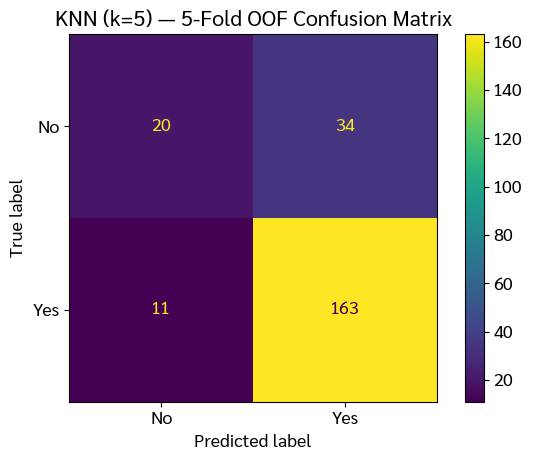

In [19]:
# ─── CLO3: Model 2 — KNN Classifier (k จาก CV ใน Part 3) ──────────
model2 = Pipeline([
    ('preprocess', make_preprocessor(numeric_cols, categorical_cols)),
    ('model', KNeighborsClassifier(n_neighbors=best_k))
])

model2.fit(X_train, y_train)
train_pred_2 = model2.predict(X_train)
train_acc_2 = accuracy_score(y_train, train_pred_2)

oof_pred_2 = cross_val_predict(
    model2, X_train, y_train, cv=cv_select, method='predict'
)
oof_acc_2 = accuracy_score(y_train, oof_pred_2)
cm2_oof = confusion_matrix(y_train, oof_pred_2)

print(f'KNN (k={best_k}) - Train Accuracy: {train_acc_2:.4f}')
print(f'KNN (k={best_k}) - 5-Fold OOF Accuracy: {oof_acc_2:.4f}')
print('\nOOF Confusion Matrix (Training Set; แถว=จริง, คอลัมน์=ทำนาย):')
print(cm2_oof)

disp = ConfusionMatrixDisplay(confusion_matrix=cm2_oof, display_labels=['No', 'Yes'])
disp.plot()
plt.title(f'KNN (k={best_k}) — 5-Fold OOF Confusion Matrix')
plt.tight_layout()
plt.show()


In [20]:
# ─── Sensitivity Check: ผลของ Feedback โดยใช้ Training-set CV ───────
categorical_cols_no_feedback = [c for c in categorical_cols if c != 'Feedback']
X_no_feedback = df[numeric_cols + categorical_cols_no_feedback]

Xnf_train, Xnf_test, ynf_train, ynf_test = train_test_split(
    X_no_feedback, y, test_size=0.20, random_state=42, stratify=y
)

model1_no_fb = Pipeline([
    ('preprocess', make_preprocessor(numeric_cols, categorical_cols_no_feedback)),
    ('model', LogisticRegression(max_iter=2000))
])

cv_with_fb = cross_val_score(
    model1, X_train, y_train, cv=cv_select, scoring='accuracy'
)
cv_without_fb = cross_val_score(
    model1_no_fb, Xnf_train, ynf_train, cv=cv_select, scoring='accuracy'
)

print('Sensitivity Check ด้วย 5-Fold CV บน Training Set:')
print(f'  Logistic Regression WITH Feedback:    {cv_with_fb.mean():.4f} ± {cv_with_fb.std():.4f}')
print(f'  Logistic Regression WITHOUT Feedback: {cv_without_fb.mean():.4f} ± {cv_without_fb.std():.4f}')
print(f'  Difference (WITH - WITHOUT):          {cv_with_fb.mean() - cv_without_fb.mean():+.4f}')

print('\nการตีความ:')
print('- การตัด Feedback ออกทำให้ CV Accuracy ลดลงอย่างชัดเจนในชุดข้อมูลนี้')
print('- ผลนี้ชี้ว่า Feedback มีข้อมูลเกี่ยวข้องกับ Output สูง')
print('- หาก Feedback ถูกบันทึกหลังการใช้บริการจริง ตัวแปรนี้อาจทำให้เกิด temporal/target leakage ในโจทย์ที่ต้องการทำนายก่อนเกิดเหตุการณ์')


Sensitivity Check ด้วย 5-Fold CV บน Training Set:
  Logistic Regression WITH Feedback:    0.8333 ± 0.0353
  Logistic Regression WITHOUT Feedback: 0.7194 ± 0.0460
  Difference (WITH - WITHOUT):          +0.1139

การตีความ:
- การตัด Feedback ออกทำให้ CV Accuracy ลดลงอย่างชัดเจนในชุดข้อมูลนี้
- ผลนี้ชี้ว่า Feedback มีข้อมูลเกี่ยวข้องกับ Output สูง
- หาก Feedback ถูกบันทึกหลังการใช้บริการจริง ตัวแปรนี้อาจทำให้เกิด temporal/target leakage ในโจทย์ที่ต้องการทำนายก่อนเกิดเหตุการณ์


**สรุป Model Comparison (ยังไม่แตะ Test Set):**

| Model | Train Accuracy | 5-Fold OOF Accuracy | รายละเอียด |
|-------|---------------:|--------------------:|----------|
| Model 1: Logistic Regression | 86.40% | **83.33%** | Linear classification หลัง One-Hot Encoding |
| Model 2: KNN (k=5) | 89.04% | **80.26%** | ใช้ระยะห่างหลัง Standardization |

**Insight:**

- Logistic Regression มี OOF Accuracy สูงกว่า KNN ใน Training-set 5-Fold CV
- KNN มี Train Accuracy สูงกว่า แต่ OOF Accuracy ต่ำกว่า จึงมีช่องว่างระหว่าง train และ OOF มากกว่า Logistic Regression ในการทดลองนี้
- **ยังไม่สรุปจาก Test Accuracy ในส่วนนี้** เพราะ Test Set ถูกสงวนไว้สำหรับ Final Evaluation หลัง Model Selection


---
## Part 5: CLO4 — Model Selection

ในส่วนนี้เปรียบเทียบ Models ด้วย **5-Fold Stratified Cross-Validation บน Training Set เท่านั้น** เพื่อป้องกันการใช้ Test Set ในขั้นตอนเลือกโมเดล

Models ที่เปรียบเทียบ:
0. **Baseline** — ทายกลุ่มส่วนใหญ่เสมอ (`DummyClassifier`)
1. **Logistic Regression**
2. **KNN (k=5)**
3. **Random Forest**

Metric หลักคือ **Accuracy** ตาม Template และรายงานค่า mean + standard deviation ของแต่ละ model นอกจากนี้ใช้แนวคิด **One-Standard-Error (1-SE) Rule** จาก Guide เพื่อช่วยเลือกโมเดลที่ง่ายกว่าเมื่อผลใกล้เคียงกัน

> **Test Set จะถูกประเมินเพียงครั้งเดียว หลังจากเลือก final model เสร็จแล้ว**


Baseline (Majority Class):
  Fold accuracies = [0.7609 0.7609 0.7609 0.7778 0.7556]
  Mean Accuracy   = 0.7632
  Std             = 0.0076

Logistic Regression:
  Fold accuracies = [0.7826 0.8261 0.8913 0.8444 0.8222]
  Mean Accuracy   = 0.8333
  Std             = 0.0353

KNN (k=5):
  Fold accuracies = [0.7826 0.7826 0.7391 0.8889 0.8222]
  Mean Accuracy   = 0.8031
  Std             = 0.0503

Random Forest:
  Fold accuracies = [0.8043 0.8478 0.8261 0.8444 0.8444]
  Mean Accuracy   = 0.8334
  Std             = 0.0164



,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean Accuracy,Std,SE
0,Random Forest,0.8043,0.8478,0.8261,0.8444,0.8444,0.8334,0.0164,0.0073
1,Logistic Regression,0.7826,0.8261,0.8913,0.8444,0.8222,0.8333,0.0353,0.0158
2,KNN (k=5),0.7826,0.7826,0.7391,0.8889,0.8222,0.8031,0.0503,0.0225
3,Baseline (Majority Class),0.7609,0.7609,0.7609,0.7778,0.7556,0.7632,0.0076,0.0034


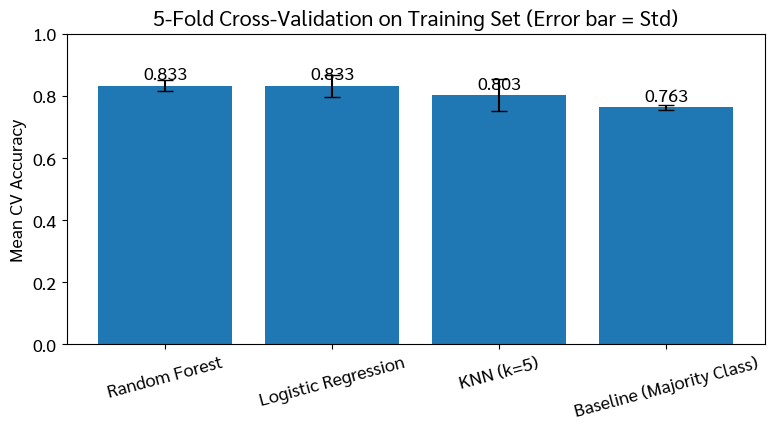

Highest mean CV accuracy: Random Forest = 0.8334
1-SE threshold = 0.8261
Models within 1-SE of the best: ['Random Forest', 'Logistic Regression']
Final model selected by 1-SE rule: Logistic Regression


In [21]:
# ─── CLO4: 5-Fold Cross-Validation บน Training Set + One-SE Rule ──────
models = {
    'Baseline (Majority Class)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': Pipeline([
        ('preprocess', make_preprocessor(numeric_cols, categorical_cols)),
        ('model', LogisticRegression(max_iter=2000))
    ]),
    f'KNN (k={best_k})': Pipeline([
        ('preprocess', make_preprocessor(numeric_cols, categorical_cols)),
        ('model', KNeighborsClassifier(n_neighbors=best_k))
    ]),
    'Random Forest': Pipeline([
        ('preprocess', make_preprocessor(numeric_cols, categorical_cols)),
        ('model', RandomForestClassifier(n_estimators=300, random_state=42))
    ])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring='accuracy'
    )
    cv_results.append({
        'Model': name,
        'Fold 1': scores[0], 'Fold 2': scores[1], 'Fold 3': scores[2],
        'Fold 4': scores[3], 'Fold 5': scores[4],
        'Mean Accuracy': scores.mean(),
        'Std': scores.std(),
        'SE': scores.std() / np.sqrt(5)
    })
    print(f'{name}:')
    print(f'  Fold accuracies = {np.round(scores, 4)}')
    print(f'  Mean Accuracy   = {scores.mean():.4f}')
    print(f'  Std             = {scores.std():.4f}')
    print()

cv_df = pd.DataFrame(cv_results).sort_values(
    'Mean Accuracy', ascending=False
).reset_index(drop=True)

display(cv_df.round(4))

# Plot
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(
    cv_df['Model'],
    cv_df['Mean Accuracy'],
    yerr=cv_df['Std'],
    capsize=6
)
ax.set_ylim(0, 1)
ax.set_ylabel('Mean CV Accuracy')
ax.set_title('5-Fold Cross-Validation on Training Set (Error bar = Std)')
ax.tick_params(axis='x', rotation=15)
for i, value in enumerate(cv_df['Mean Accuracy']):
    ax.text(i, value + 0.02, f'{value:.3f}', ha='center')
plt.tight_layout()
plt.show()


non_baseline = cv_df[~cv_df['Model'].str.contains('Baseline')].copy()
best_row = non_baseline.iloc[0]
threshold = best_row['Mean Accuracy'] - best_row['SE']
within_1se = non_baseline[
    non_baseline['Mean Accuracy'] >= threshold
].copy()

print(f'Highest mean CV accuracy: {best_row["Model"]} = {best_row["Mean Accuracy"]:.4f}')
print(f'1-SE threshold = {threshold:.4f}')
print('Models within 1-SE of the best:', within_1se['Model'].tolist())

simplicity_order = {
    'Logistic Regression': 0,
    f'KNN (k={best_k})': 1,
    'Random Forest': 2
}
within_1se['simplicity_rank'] = within_1se['Model'].map(simplicity_order)
selected_model_name = within_1se.sort_values('simplicity_rank').iloc[0]['Model']

print(f'Final model selected by 1-SE rule: {selected_model_name}')


### ผล Model Selection

- **โมเดลที่มี Mean CV Accuracy สูงสุด:** Random Forest ≈ **83.34%**
- **Logistic Regression:** ≈ **83.33%**
- ผลของสองโมเดลนี้แตกต่างกันเพียงประมาณ **0.01 จุดเปอร์เซ็นต์** จึงไม่ควรกล่าวว่า Random Forest ชนะอย่างชัดเจน
- เมื่อใช้ **1-SE Rule** ทั้ง Logistic Regression และ Random Forest อยู่ในช่วง 1-SE ของโมเดลที่ดีที่สุด
- เลือก **Logistic Regression เป็น Final Model** เพราะมีความซับซ้อนต่ำกว่าและตีความ coefficients ได้ง่ายกว่า ในขณะที่ CV performance ใกล้เคียงกับ Random Forest มาก

การตัดสินใจนี้ใช้ **Training Set เท่านั้น** และยังไม่ได้ใช้ Test Set


### Final Evaluation: ประเมิน Final Model บน Test Set ครั้งเดียว

หลังจาก Model Selection เสร็จแล้ว จึงนำ **Test Set ที่ไม่ได้ใช้ในการฝึกหรือเลือกโมเดล** มาใช้ประเมิน Final Model เพียงครั้งเดียว เพื่อให้ได้ภาพสะท้อนของ generalization ที่ลดความเสี่ยงจาก optimistic bias

=== Final Model: Logistic Regression ===
Test Accuracy: 0.8246 (82.46%)
Test Baseline Accuracy: 0.7544 (75.44%)
Majority Class learned from Training Set: Yes
Improvement over baseline: +7.02 percentage points

Classification Report:
              precision    recall  f1-score   support

          No      0.700     0.500     0.583        14
         Yes      0.851     0.930     0.889        43

    accuracy                          0.825        57
   macro avg      0.776     0.715     0.736        57
weighted avg      0.814     0.825     0.814        57

Confusion Matrix (แถว=จริง, คอลัมน์=ทำนาย):
[[ 7  7]
 [ 3 40]]


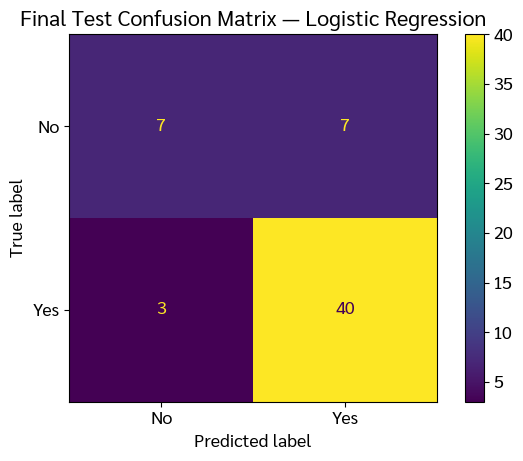

In [22]:
# ─── Final Evaluation: Test Set ถูกใช้ครั้งเดียวหลัง Model Selection ──
final_model = models[selected_model_name]
final_model.fit(X_train, y_train)

y_pred_final = final_model.predict(X_test)

final_test_accuracy = accuracy_score(y_test, y_pred_final)
final_cm = confusion_matrix(y_test, y_pred_final)


majority_class = y_train.mode()[0]
test_baseline_pred = np.full(len(y_test), majority_class)
test_baseline_accuracy = accuracy_score(y_test, test_baseline_pred)

print(f'=== Final Model: {selected_model_name} ===')
print(f'Test Accuracy: {final_test_accuracy:.4f} ({final_test_accuracy*100:.2f}%)')
print(f'Test Baseline Accuracy: {test_baseline_accuracy:.4f} ({test_baseline_accuracy*100:.2f}%)')
print(f'Majority Class learned from Training Set: {"Yes" if majority_class == 1 else "No"}')
print(f'Improvement over baseline: {(final_test_accuracy - test_baseline_accuracy)*100:+.2f} percentage points')

print('\nClassification Report:')
print(classification_report(
    y_test, y_pred_final,
    target_names=['No', 'Yes'],
    digits=3
))

print('Confusion Matrix (แถว=จริง, คอลัมน์=ทำนาย):')
print(final_cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=final_cm,
    display_labels=['No', 'Yes']
)
disp.plot()
plt.title(f'Final Test Confusion Matrix — {selected_model_name}')
plt.tight_layout()
plt.show()


---
## Part 6: สรุปผลและ Data Story

### 6.1 สรุปผลการวิเคราะห์

- **CLO1 (PCA):** หลังไม่ใช้ `Pin code` ซึ่งมี category จำนวนมากเมื่อเทียบกับขนาดข้อมูล ชุด feature สำหรับ PCA เหลือ 28 dimensions; PC1 อธิบายความแปรปรวน **23.38%** และ 5 PC แรกอธิบายได้ **71.08%** โดย PC1 มี loading สูงใน Age/Family size และบางระดับของ demographic ขณะที่ PC2 มี loading สูงใน latitude/longitude
- **CLO2 (Statistical Learning):** Dataset เป็น **Binary Classification** และมี class imbalance โดย Overall Majority Proportion หลัง cleaning = **76.14%**. `Feedback` มี absolute correlation กับ Output สูงที่สุด (~0.55). การเลือก KNN hyperparameter แบบไม่แตะ Test Set ได้ **k=5** และ CV Accuracy ≈ **80.31%**
- **CLO3 (Model Building):** ใน Training-set 5-Fold OOF, Logistic Regression ได้ Accuracy **83.33%** และ KNN (k=5) ได้ **80.26%**. Sensitivity Check พบว่าเมื่อเอา Feedback ออก Logistic Regression มี CV Accuracy ลดลงเหลือประมาณ **71.94%**
- **CLO4 (Model Selection):** Random Forest มี Mean CV Accuracy สูงสุดประมาณ **83.34%** ขณะที่ Logistic Regression ได้ประมาณ **83.33%** ซึ่งใกล้กันมาก ภายใต้ 1-SE Rule จึงเลือก **Logistic Regression** เพราะง่ายต่อการตีความกว่า
- **Final Evaluation:** หลัง Model Selection จึงใช้ Test Set ที่ไม่ได้ใช้ในการฝึกหรือเลือกโมเดลเพื่อประเมินครั้งเดียว โดย Logistic Regression ได้ **Test Accuracy 82.46%** ขณะที่ **Test Baseline = 75.44%** (majority class จาก Training Set) หรือสูงกว่า Baseline **7.02 จุดเปอร์เซ็นต์**. อย่างไรก็ตาม Recall ของกลุ่ม `No` ยังต่ำกว่ากลุ่ม `Yes` จึงไม่ควรดู Accuracy เพียงอย่างเดียว

### 6.2 Limitations

1. **ขนาดข้อมูลเล็ก:** หลังลบ duplicate เหลือ 285 แถว ทำให้ผลการประเมินต่อ fold และต่อ test split มีความผันผวนได้
2. **การลบ duplicate เป็นข้อสมมติ:** Dataset ไม่มี customer ID จึงยืนยันไม่ได้ว่าแถวที่เหมือนกันทั้งหมดเป็น duplicate จริงหรือเป็นผู้ตอบคนละคนที่มีข้อมูลเหมือนกัน
3. **Feedback อาจเกิดหลังการใช้บริการ:** หากเป็นเช่นนั้น การใช้ Feedback เพื่อทำนายการตัดสินใจก่อนสั่งอาหารจะมีความเสี่ยงต่อ temporal/target leakage
4. **Class Imbalance:** Output มีสัดส่วน Yes มากกว่า No ทำให้ Accuracy อาจดูดีแม้ความสามารถในการจับกลุ่ม No ยังต่ำ
5. **Features ไม่ครบมิติทางธุรกรรม:** Dataset ไม่มีข้อมูล เช่น ราคาอาหาร จำนวน order หรือ delivery time จึงวิเคราะห์พฤติกรรมการสั่งซื้อเชิงธุรกรรมโดยตรงไม่ได้

### 6.3 ขั้นตอนต่อไป (Future Work)

- เพิ่ม customer ID และข้อมูลช่วงเวลา เพื่อยืนยัน duplicate และวิเคราะห์ลำดับเหตุการณ์ได้ชัดเจนขึ้น
- หากโจทย์คือการทำนายก่อนเกิดการสั่งซื้อ ควรตัด Feedback ออกจากโมเดลใช้งานจริง และเก็บเฉพาะ feature ที่มีอยู่ก่อนการตัดสินใจ
- เพิ่มตัวแปรเชิงธุรกรรม เช่น จำนวนคำสั่งซื้อ ค่าใช้จ่ายเฉลี่ย ระยะเวลาจัดส่ง และระยะทาง
- ใช้ Precision, Recall, F1-score หรือ Balanced Accuracy ควบคู่กับ Accuracy เพื่อรับมือกับ class imbalance
- ทดลองจัดกลุ่ม Pin code ที่มีตัวอย่างน้อย หรือสร้าง feature เชิงพื้นที่ที่เหมาะสมกว่าในอนาคต

### 6.4 Connection กับ Topics ในวิชา

- **CLO1 / Linear Algebra:** One-Hot Encoding, Standardization และ PCA เพื่อการลดมิติและวิเคราะห์โครงสร้างของ feature matrix
- **CLO2 / Statistical Learning:** Distribution, Correlation และ Bias-Variance Trade-off รวมถึงการแยก Training/Test และการระวัง Data Leakage
- **CLO3 / Classification:** Logistic Regression และ KNN
- **CLO4 / Model Selection:** 5-Fold Stratified Cross-Validation, 1-SE Rule, Baseline และ Final Test Evaluation

---

**Acknowledgements:**  
ขอขอบคุณแหล่งข้อมูล Dataset, ผู้สอนและเอกสาร Template/Guide สำหรับแนวทางการทำโครงงาน และ Python/Scikit-learn สำหรับการวิเคราะห์ข้อมูลและสร้างแบบจำลอง
